# Preprocessing and Cohort Filtering

Shows how raw CGM files become analysis-ready 45-day windows (sampling-interval detection → quality flags → optimal-coverage window), then applies the cohort filter **median glucose ∈ [110, 170] mg/dL**.

Equivalent scripts: `python3 -m scripts.preprocessing.cgm_preprocessing` and `python3 -m scripts.preprocessing.cgm_filtering`.

**Usage** — from the repository root, point the notebook at a data folder and open it
(the open BrisT1D example data converted to glucose-only files is enough: `make brist1d_run`):

```bash
CGM_DATA_ROOT=$PWD/example_data/BrisT1D/converted jupyter lab notebooks/
```

**Authors:** Guillaume Deside, Laura Symul, Philippe Lysy, Zain Syed

> **Illustration only.** This notebook is run on the open **BrisT1D-Open** example data (Gordon James et al. 2025, CC BY 4.0), converted by `make brist1d` to glucose-only files (mg/dL, 5-min grid; see the README). These are not the study data: the numbers and figures illustrate what the code does and are not expected to match the manuscript, nor are they findings about BrisT1D.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import (
    RAW_PATH, PATIENT_ID_COL, TIME_COL, GLUCOSE_COL,
    WINDOW_SUMMARY_CSV, PATIENTS_STATUS_CSV, METRICS_CSV,
    FIG_FILTERING_DIR, FILTER_DIR_PATH,
    COL_HAS_WINDOW, COL_COVERAGE_PCT, COL_DOMINANT_STEP, COL_FILEPATH,
    COL_FLAG_TIME_ERROR, COL_FLAG_OUTLIER_GLUCOSE,
    WINDOW_DAYS, MIN_COVERAGE_PCT,
)
from src.preprocessing.load_data import load_patient_raw_data, load_patient_window
from src.preprocessing.timestep import detect_dominant_sampling_interval
from src.preprocessing.quality import attach_quality_flags
from src.preprocessing.window import find_optimal_window

from src.metrics.load_metrics import load_patient_metrics
from src.filtering.filtering import apply_median_glucose_filter
from src.filtering.filtering_config import (
    MEDIAN_GLUCOSE_MIN, MEDIAN_GLUCOSE_MAX, COL_MEDIAN_GLUCOSE, COL_CV, COL_TIR,
)
from src.visualization.filtering_plots import generate_histogram_figure, generate_scatter_figure

%matplotlib inline

from IPython.display import SVG, display


def show_saved(directory, prefix):
    """Display the saved SVG whose name starts with *prefix* (the figure helpers save and close the figure)."""
    matches = sorted(Path(directory).glob(f"{prefix}*.svg"))
    if matches:
        display(SVG(filename=str(matches[0])))
    else:
        print(f"No saved figure starting with '{prefix}' in {directory}")

---
## 2. Preprocessing — one patient, step by step

For each patient the pipeline

1. loads the raw file (`time`, `glycemie`) and detects the **dominant sampling interval**;
2. attaches **quality flags** — unexpectedly short intervals (time errors), gaps, and glucose outliers;
3. slides a window of `WINDOW_DAYS` days over the recording and keeps the position with the **highest share of valid readings**
   (it must reach `MIN_COVERAGE_PCT`).

In [2]:
patients = sorted(p.stem for p in Path(RAW_PATH).glob("*.xlsx"))
patient_id = patients[0]

raw = load_patient_raw_data(patient_id, str(RAW_PATH))
step_min = detect_dominant_sampling_interval(raw)

print(f"Patient {patient_id}: {len(raw)} raw readings, "
      f"{raw[TIME_COL].min():%Y-%m-%d} → {raw[TIME_COL].max():%Y-%m-%d}")
print(f"Dominant sampling interval: {step_min:.0f} min")

Patient P01: 18952 raw readings, 2023-06-01 → 2023-12-20
Dominant sampling interval: 15 min


In [3]:
flagged = attach_quality_flags(raw, step_min)

flag_counts = flagged[[c for c in flagged.columns if c.startswith("flag_")]].sum()
flag_counts.rename("n readings flagged").to_frame()

,n readings flagged
flag_time_error,4
flag_gap_before,32
flag_outlier_glucose,10


In [4]:
window = find_optimal_window(flagged, step_min)

print(f"Window: {window['win_start']:%Y-%m-%d} → {window['win_end']:%Y-%m-%d} "
      f"({WINDOW_DAYS} days)")
print(f"Coverage: {window['coverage_pct']:.1f}%  "
      f"({window['n_valid']} valid / {window['n_total']} expected readings; minimum {MIN_COVERAGE_PCT}%)")

Window: 2023-10-28 → 2023-12-12 (45 days)
Coverage: 99.0%  (4278 valid / 4282 expected readings; minimum 70.0%)


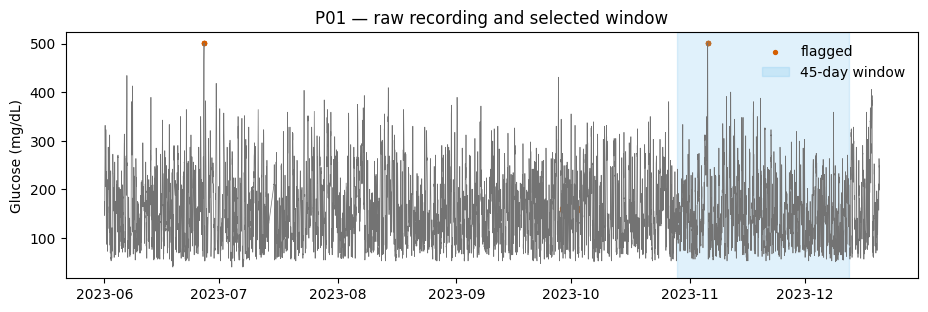

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.2))
bad = flagged[COL_FLAG_TIME_ERROR] | flagged[COL_FLAG_OUTLIER_GLUCOSE]

ax.plot(flagged[TIME_COL], flagged[GLUCOSE_COL], lw=0.5, color="0.45")
ax.scatter(flagged.loc[bad, TIME_COL], flagged.loc[bad, GLUCOSE_COL], s=8, color="#D55E00", label="flagged")
ax.axvspan(window["win_start"], window["win_end"], color="#56B4E9", alpha=0.18, label=f"{WINDOW_DAYS}-day window")
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title(f"{patient_id} — raw recording and selected window")
ax.legend(loc="upper right", frameon=False)
plt.show()

### Cohort result

The pipeline writes `windows_summary.csv` (patients that obtained a window) and `patients_status.csv`
(every patient, with or without a window).

In [6]:
status = pd.read_csv(PATIENTS_STATUS_CSV)
windows = pd.read_csv(WINDOW_SUMMARY_CSV)

print(f"Patients processed:       {len(status)}")
print(f"Patients with a window:   {len(windows)}")
print(f"Patients without window:  {len(status) - len(windows)}")
windows.drop(columns=[COL_FILEPATH]).head()

Patients processed:       20
Patients with a window:   15
Patients without window:  5


,patient_id,win_start,win_end,coverage_pct,flag_rate_pct,n_valid,n_total,dominant_step_min,filename
0,P02,2023-06-24 06:00:00,2023-08-08 06:00:00,98.60,-0.01,12779,12778,5.0,P02_win1_2023-06-24_to_2023-08-08_cov99pct.xlsx
1,P03,2023-06-07 00:05:00,2023-07-22 00:05:00,99.14,-0.01,12849,12848,5.0,P03_win1_2023-06-07_to_2023-07-22_cov99pct.xlsx
2,P04,2023-09-02 00:00:00,2023-10-17 00:00:00,99.14,-0.01,12848,12847,5.0,P04_win1_2023-09-02_to_2023-10-16_cov99pct.xlsx
3,P07,2023-06-15 02:00:00,2023-07-30 02:00:00,98.29,-0.01,12738,12737,5.0,P07_win1_2023-06-15_to_2023-07-30_cov98pct.xlsx
4,P10,2023-06-21 18:05:00,2023-08-05 18:05:00,98.06,-0.01,12709,12708,5.0,P10_win1_2023-06-21_to_2023-08-05_cov98pct.xlsx


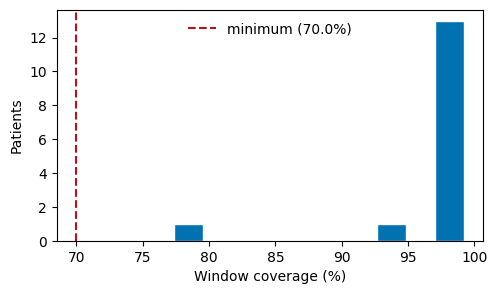

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.hist(windows[COL_COVERAGE_PCT], bins=10, color="#0072B2", edgecolor="white")
ax.axvline(MIN_COVERAGE_PCT, color="#B5121B", ls="--", label=f"minimum ({MIN_COVERAGE_PCT}%)")
ax.set_xlabel("Window coverage (%)"); ax.set_ylabel("Patients"); ax.legend(frameon=False)
plt.show()

---
## 3. Filtering — median glucose criterion

**Median glucose ∈ [110, 170] mg/dL** keeps patients with typical type 1 diabetes control and excludes

- very well-controlled patients (median < 110 mg/dL), who may have almost no SLH episodes;
- poorly controlled patients (median > 170 mg/dL), where long-lasting hyperglycaemia dominates.

The filter is applied to the metrics table produced by the metrics notebook (`01_cgm_metrics.ipynb`).

In [8]:
df_all = load_patient_metrics(METRICS_CSV)
df_selected = apply_median_glucose_filter(df_all)

n_total, n_selected = len(df_all), len(df_selected)
print(f"Criterion: median glucose in [{MEDIAN_GLUCOSE_MIN}, {MEDIAN_GLUCOSE_MAX}] mg/dL")
print(f"Selected: {n_selected} / {n_total} ({n_selected / n_total:.0%})")
print(f"Excluded: {n_total - n_selected} / {n_total}")

  Loaded 15 patients with valid metrics
Criterion: median glucose in [110, 170] mg/dL
Selected: 14 / 15 (93%)
Excluded: 1 / 15


In [9]:
selected_ids = set(df_selected[PATIENT_ID_COL])
df_all["selected"] = df_all[PATIENT_ID_COL].isin(selected_ids)

df_all.groupby("selected")[[COL_MEDIAN_GLUCOSE, COL_CV, COL_TIR]].describe().round(2).T

selected                False   True 
Median_glycemia count    1.00   14.00
                mean   108.10  144.65
                std       NaN   13.18
                min    108.10  124.30
                25%    108.10  135.10
                50%    108.10  143.20
                75%    108.10  156.35
                max    108.10  165.80
CV              count    1.00   14.00
                mean     0.24    0.34
                std       NaN    0.05
                min      0.24    0.23
                25%      0.24    0.31
                50%      0.24    0.35
                75%      0.24    0.36
                max      0.24    0.40
TIR70180        count    1.00   14.00
                mean     0.96    0.71
                std       NaN    0.08
                min      0.96    0.56
                25%      0.96    0.68
                50%      0.96    0.73
                75%      0.96    0.77
                max      0.96    0.82

### Figures

The plotting helpers save each figure (PDF + SVG) to `Figures/Filtering/`; the SVG is displayed below.

Saved: median_glucose_histogram_mgdl.{pdf,svg}  (DPI: 600)


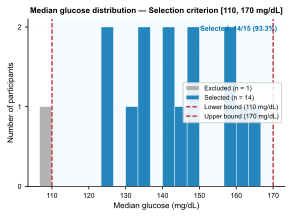

In [10]:
generate_histogram_figure(df_all, df_selected, FIG_FILTERING_DIR)
show_saved(FIG_FILTERING_DIR, "median_glucose_histogram")

Saved: median_vs_cv_scatter_mgdl.{pdf,svg}  (DPI: 600)


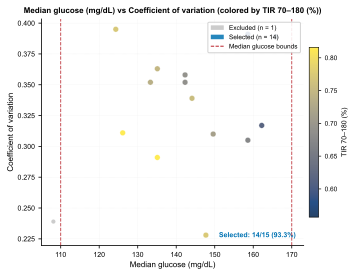

In [11]:
generate_scatter_figure(df_all, df_selected, COL_MEDIAN_GLUCOSE, COL_CV, COL_TIR, FIG_FILTERING_DIR)
show_saved(FIG_FILTERING_DIR, "median_vs_cv_scatter")

Saved: median_vs_tir70180_scatter_mgdl.{pdf,svg}  (DPI: 600)


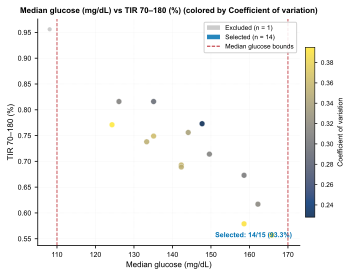

In [12]:
generate_scatter_figure(df_all, df_selected, COL_MEDIAN_GLUCOSE, COL_TIR, COL_CV, FIG_FILTERING_DIR)
show_saved(FIG_FILTERING_DIR, "median_vs_tir70180_scatter")

Saved: cv_vs_tir70180_scatter_mgdl.{pdf,svg}  (DPI: 600)


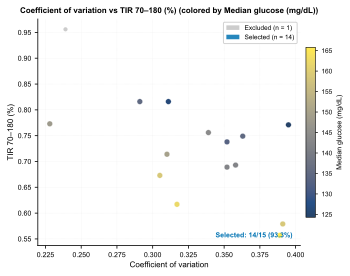

In [13]:
generate_scatter_figure(df_all, df_selected, COL_CV, COL_TIR, COL_MEDIAN_GLUCOSE, FIG_FILTERING_DIR)
show_saved(FIG_FILTERING_DIR, "cv_vs_tir70180_scatter")

### Selected cohort

The pipeline script saves the status table and the list of selected IDs to `Data/Filtered/`; later steps only read that list.

In [14]:
sorted(selected_ids)

['P02',
 'P03',
 'P04',
 'P07',
 'P11',
 'P12',
 'P15',
 'P16',
 'P17',
 'P18',
 'P19',
 'P22',
 'P23',
 'P24']